In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
os.chdir('/content/drive/MyDrive/DataACQ/DAQProject')
!pwd

/content/drive/MyDrive/DataACQ/DAQProject


In [ ]:
# core data handling
import pandas as pd
import numpy as np
import re

# plotting (Seaborn is required for your project)
import matplotlib.pyplot as plt
import seaborn as sns

# stats and analysis
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf


Merging


In [ ]:
import pandas as pd, re, unicodedata

def clean(s):
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().lower().strip()
    s = re.sub(r"[^a-z0-9 ]", " ", s)
    return re.sub(r"\s+", " ", s).strip()


#Dictionary for brand and body type
MAKE_ALIASES = {"vw": "volkswagen", "merc": "mercedes benz", "mercedes": "mercedes benz",
                "alfa": "alfa romeo", "landrover": "land rover"}

MODEL_ALIASES = {
    "grand c max": "c max", "grand scenic": "scenic", "grand c4 picasso": "c4 picasso",
    "golf variant": "golf", "golf sportsvan": "golf", "golf plus": "golf",
    "passat variant": "passat", "tiguan allspace": "tiguan",
    "a klasse": "a class", "b klasse": "b class", "c klasse": "c class",
    "e klasse": "e class", "s klasse": "s class",
    "cee d": "ceed", "ceed cee d": "ceed", "yaris hybrid": "yaris", "500c": "500",
    "crossland": "crossland x", "mokka x": "mokka",
    "cooper s": "cooper", "cooper se": "cooper", "cooper d": "cooper", "one": "cooper",
    "t6 multivan": "multivan", "t6 1 multivan": "multivan",
}

BODY_WORDS = {"variant", "avant", "sportback", "combi", "kombi", "estate", "touring", "wagon",
              "sw", "sportsvan", "hatchback", "saloon", "sedan", "coupe", "cabrio",
              "cabriolet", "convertible", "roadster"}

def model_key(model, make=None):
    m = clean(model)
    mk = MAKE_ALIASES.get(clean(make), clean(make)) if make is not None else None
    if mk and m.startswith(mk + " "):
        m = m[len(mk) + 1:]
    if mk == "bmw":
        mm = re.match(r"^([1-8])\d\d[a-z]*$", m)
        if mm: m = f"{mm.group(1)} series"
    if mk == "mercedes benz":
        mm = re.match(r"^(gl[abcekse]|cl[ak]|[abceghmsv]) ?\d{2,3}[a-z]*$", m)
        if mm:
            g = mm.group(1)
            m = g if len(g) > 1 else f"{g} class"
    m = MODEL_ALIASES.get(m, m)
    m = " ".join(t for t in m.split() if t not in BODY_WORDS)
    return m.replace(" ", "")

In [ ]:
df = pd.read_csv("UsedCarKaggleDataCleaned2.csv")

for c in ["year", "price_in_euro", "power_kw", "power_ps"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

bad = df["year"].isna() | df["price_in_euro"].isna() | ~df["year"].between(1990, 2026)
print("Corrupt rows removed:", bad.sum())

df = df[~bad].drop(columns="Unnamed: 0").drop_duplicates().copy()
df["year"] = df["year"].astype(int)

df["make_k"] = df["brand"].map(lambda x: MAKE_ALIASES.get(clean(x), clean(x)))
df["model_k"] = df.apply(lambda r: model_key(r["model"], r["brand"]), axis=1)
print(len(df), "rows")

Corrupt rows removed: 199
244542 rows


In [ ]:
ncap = pd.read_csv("euroncap_assessments.csv")

ncap["make_k"] = ncap["make"].map(lambda x: MAKE_ALIASES.get(clean(x), clean(x)))
ncap["model_k"] = ncap.apply(lambda r: model_key(r["model"], r["make"]), axis=1)

# one row per model per test year (base variant first)
ncap = (ncap.sort_values(["make_k", "model_k", "protocol_year", "variant_suffix"], na_position="first")
            .drop_duplicates(["make_k", "model_k", "protocol_year"]))

keep = ["make_k", "model_k", "protocol_year", "scheme", "stars", "adult_occupant_pct",
        "child_occupant_pct", "vulnerable_road_users_pct", "safety_assist_pct",
        "body_type", "kerb_weight_kg"]

In [ ]:
merged = pd.merge_asof(
    df.sort_values("year"),
    ncap.sort_values("protocol_year")[keep],
    left_on="year",
    right_on="protocol_year",
    by=["make_k", "model_k"],
    direction="backward",
    tolerance=5,
)

merged["rating_age"] = merged["year"] - merged["protocol_year"]
merged["matched"] = merged["protocol_year"].notna()

print("Rows before:", len(df), "| after:", len(merged))
print("Matched:", merged["matched"].sum(), f"({merged['matched'].mean():.1%})")

Rows before: 244542 | after: 244542
Matched: 71788 (29.4%)


In [ ]:
# which models still miss (cars from 2017 on)
print(merged[(~merged["matched"]) & (merged["year"] >= 2017)]
      .groupby(["make_k", "model_k"]).size().sort_values(ascending=False).head(30))

merged.to_csv("merged_cars_ncap.csv", index=False)
matched = merged[merged["matched"]].copy()   # use this for plots and models

make_k         model_k 
seat           ateca       1899
opel           astra       1805
mini           cooper      1637
volkswagen     golf        1514
seat           leon        1503
mercedes benz  eclass      1340
audi           a4          1335
skoda          superb      1285
volkswagen     tiguan      1262
skoda          octavia     1011
volkswagen     passat      1004
peugeot        3008         800
skoda          fabia        796
ford           ecosport     725
audi           a3           721
               a5           708
bmw            2series      698
mercedes benz  glc          690
renault        megane       672
kia            sportage     626
hyundai        tucson       620
renault        kadjar       607
smart          fortwo       604
audi           q2           565
mercedes benz  vclass       524
opel           mokka        513
nissan         qashqai      488
bmw            x1           481
fiat           tipo         464
ford           smax         450
dtype: int64


Analysis and exploration

Question: **Does the Euro NCAP rating affect the price of used car prices in Germany?**

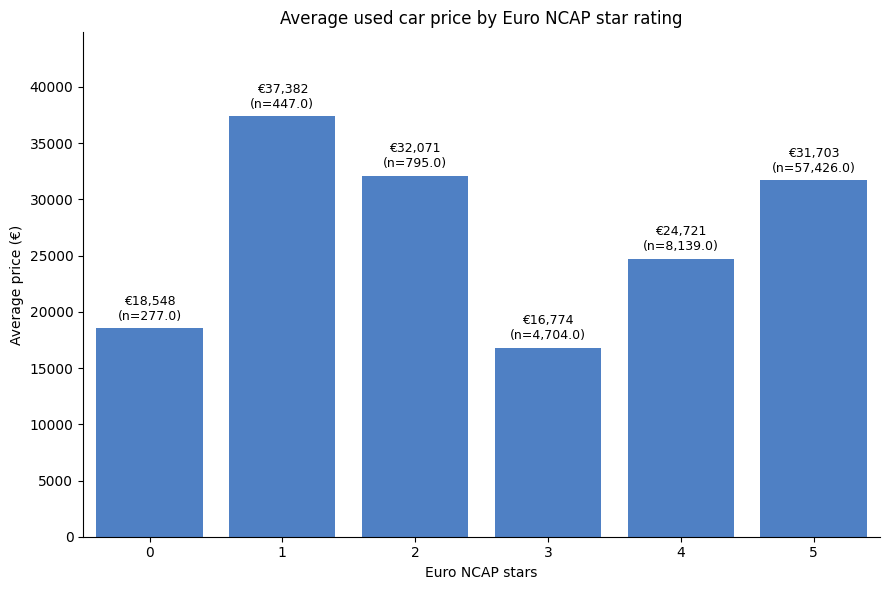

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

a = merged[merged["matched"]].copy()
a["stars"] = a["stars"].astype(int)

avg = a.groupby("stars")["price_in_euro"].agg(["mean", "count"]).reset_index()

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(data=avg, x="stars", y="mean", color="#3b7dd8", ax=ax)

for i, row in avg.iterrows():
    ax.text(i, row["mean"] + 500, f"€{row['mean']:,.0f}\n(n={row['count']:,})",
            ha="center", va="bottom", fontsize=9)

ax.set_title("Average used car price by Euro NCAP star rating")
ax.set_xlabel("Euro NCAP stars")
ax.set_ylabel("Average price (€)")
ax.set_ylim(0, avg["mean"].max() * 1.2)
sns.despine()
plt.tight_layout()
plt.show()

In [ ]:
top = (merged[merged["matched"]]
       .sort_values("price_in_euro", ascending=False)
       .groupby("stars").head(1)
       .sort_values("stars")[["stars", "brand", "model", "year", "price_in_euro", "mileage_in_km"]])
print(top)

        stars    brand          model  year  price_in_euro  mileage_in_km
203585    0.0  renault    Renault ZOE  2021        68490.0        12136.0
217673    1.0     jeep  Jeep Wrangler  2022       129000.0           50.0
208405    2.0     ford   Ford Mustang  2022       148700.0         1900.0
185671    3.0     jeep  Jeep Renegade  2020       214990.0        18393.0
185696    4.0     jeep  Jeep Cherokee  2020       102399.0        17000.0
123087    5.0      bmw        BMW 550  2018      1010101.0        87000.0


The chart shows no steady link between Euro Ncap rating and used car prices.The bars rise and fall instead of climbing, and the tallest column (1 and 2 stars) rest on only a few hundred cars, so they swing with a few expensive niche models such as the jeep wrangler and ford mustang.

The 3 to 5 star groups hold the most cars (around 65,000) and these show signs of what we were looking for, the steady increase correlated to the safety ratings.

From this, I would say the Euro Ncap rating is a weak driver of price in this study.

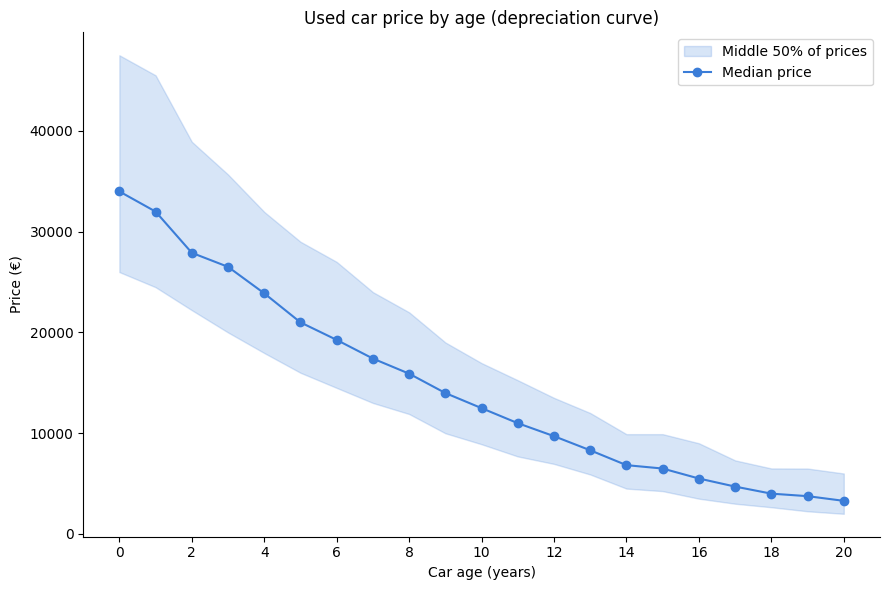

In [ ]:
import numpy as np, matplotlib.pyplot as plt, seaborn as sns

p = df.copy()
p["car_age"] = 2023 - p["year"]

# median price and number of cars at each age
curve = (p.groupby("car_age")["price_in_euro"]
           .agg(median="median", q25=lambda s: s.quantile(0.25),
                q75=lambda s: s.quantile(0.75), n="size")
           .reset_index())
curve = curve[(curve["car_age"] <= 20) & (curve["n"] >= 500)]   # drop thin tail

fig, ax = plt.subplots(figsize=(9, 6))
ax.fill_between(curve["car_age"], curve["q25"], curve["q75"], alpha=0.2, color="#3b7dd8",
                label="Middle 50% of prices")
ax.plot(curve["car_age"], curve["median"], marker="o", color="#3b7dd8", label="Median price")

ax.set_title("Used car price by age (depreciation curve)")
ax.set_xlabel("Car age (years)")
ax.set_ylabel("Price (€)")
ax.set_xticks(range(0, 21, 2))
ax.legend()
sns.despine()
plt.tight_layout()
plt.show()

As we can see from this, Age is a huge factor in the price of cars, Unfortunately the Euro NCAP only covers cars from 2017 onwards

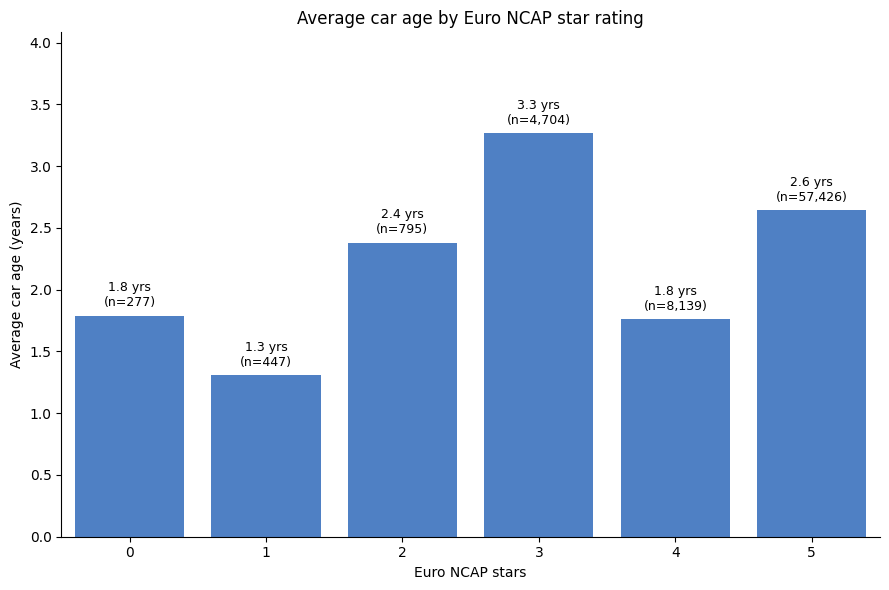

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

a = merged[merged["matched"]].copy()
a["stars"] = a["stars"].astype(int)
a["car_age"] = 2023 - a["year"]

avg = a.groupby("stars")["car_age"].agg(["mean", "count"]).reset_index()

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(data=avg, x="stars", y="mean", color="#3b7dd8", ax=ax)

for i, row in avg.iterrows():
    ax.text(i, row["mean"] + 0.05, f"{row['mean']:.1f} yrs\n(n={int(row['count']):,})",
            ha="center", va="bottom", fontsize=9)

ax.set_title("Average car age by Euro NCAP star rating")
ax.set_xlabel("Euro NCAP stars")
ax.set_ylabel("Average car age (years)")
ax.set_ylim(0, avg["mean"].max() * 1.25)
sns.despine(); plt.tight_layout(); plt.show()

In [ ]:
I expected this data to more linear, i expected lower star rating cars to be older.

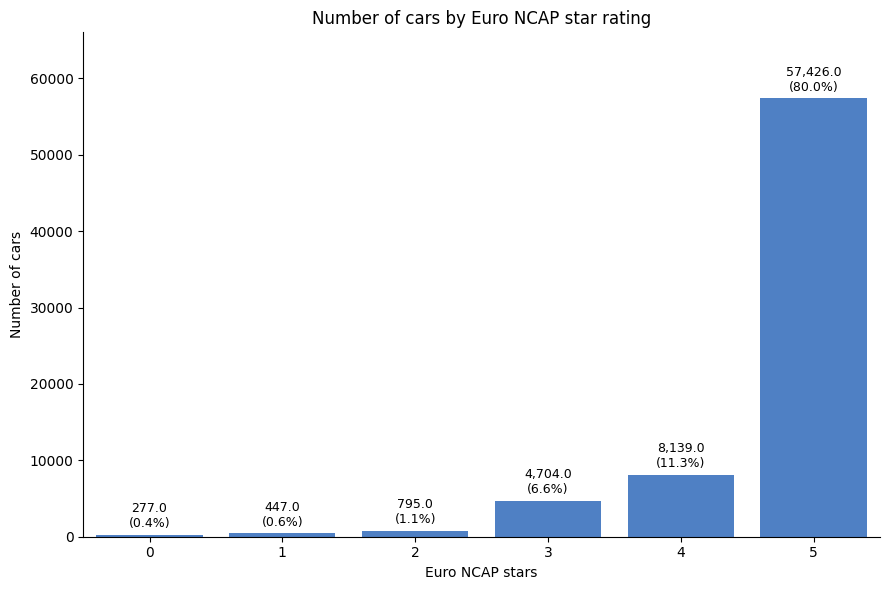

   stars   cars      share
0      0    277   0.385858
1      1    447   0.622667
2      2    795   1.107427
3      3   4704   6.552627
4      4   8139  11.337549
5      5  57426  79.993871


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

a = merged[merged["matched"]].copy()
a["stars"] = a["stars"].astype(int)

counts = a["stars"].value_counts().sort_index().reset_index()
counts.columns = ["stars", "cars"]
counts["share"] = counts["cars"] / counts["cars"].sum() * 100

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(data=counts, x="stars", y="cars", color="#3b7dd8", ax=ax)

for i, row in counts.iterrows():
    ax.text(i, row["cars"] + counts["cars"].max() * 0.01,
            f"{row['cars']:,}\n({row['share']:.1f}%)", ha="center", va="bottom", fontsize=9)

ax.set_title("Number of cars by Euro NCAP star rating")
ax.set_xlabel("Euro NCAP stars")
ax.set_ylabel("Number of cars")
ax.set_ylim(0, counts["cars"].max() * 1.15)
sns.despine(); plt.tight_layout(); plt.show()

print(counts)

As we can see here, majority of cars are 5 star rated(80%) which would be difficult to see how the price could be affected with this spread of data.

What it does show us is that most cars from 2017 onwards are safe for the roads with majority of them being 5 stars.

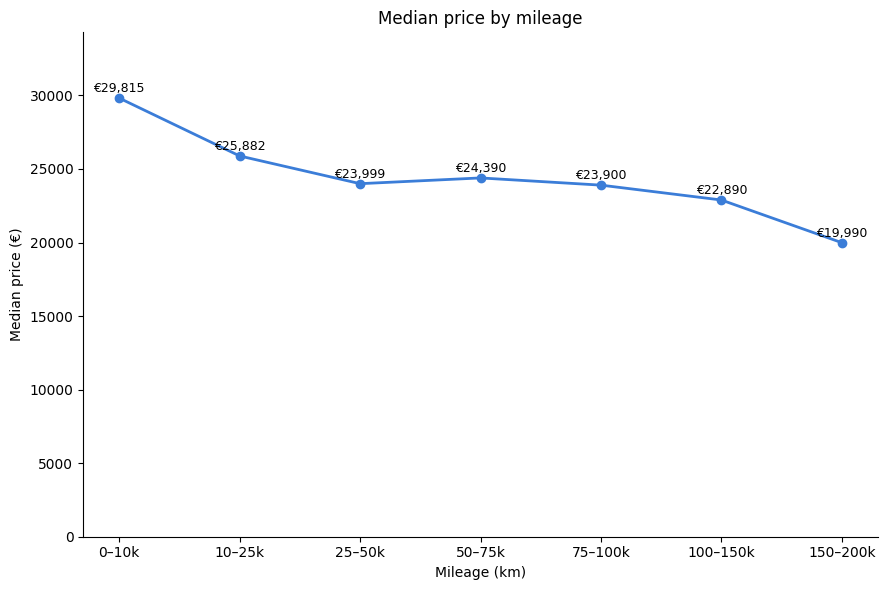

In [ ]:
import pandas as pd, matplotlib.pyplot as plt, seaborn as sns

a = merged[merged["matched"]].copy()
a["mileage_in_km"] = pd.to_numeric(a["mileage_in_km"], errors="coerce")
a = a.dropna(subset=["mileage_in_km"])

bins = [0, 10000, 25000, 50000, 75000, 100000, 150000, 200000]
a["band"] = pd.cut(a["mileage_in_km"], bins, include_lowest=True)

trend = (a.groupby("band", observed=True)["price_in_euro"]
           .median().reset_index())
trend["label"] = ["0–10k", "10–25k", "25–50k", "50–75k", "75–100k", "100–150k", "150–200k"][:len(trend)]

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(trend["label"], trend["price_in_euro"], marker="o", color="#3b7dd8", linewidth=2)

for x, y in zip(trend["label"], trend["price_in_euro"]):
    ax.text(x, y + 400, f"€{y:,.0f}", ha="center", fontsize=9)

ax.set_title("Median price by mileage")
ax.set_xlabel("Mileage (km)")
ax.set_ylabel("Median price (€)")
ax.set_ylim(0, trend["price_in_euro"].max() * 1.15)
sns.despine(); plt.tight_layout(); plt.show()

This graph helps solidify that price is directly affected by the mileage of the car, this is to be expected as the cars have been used less making them more valuable.

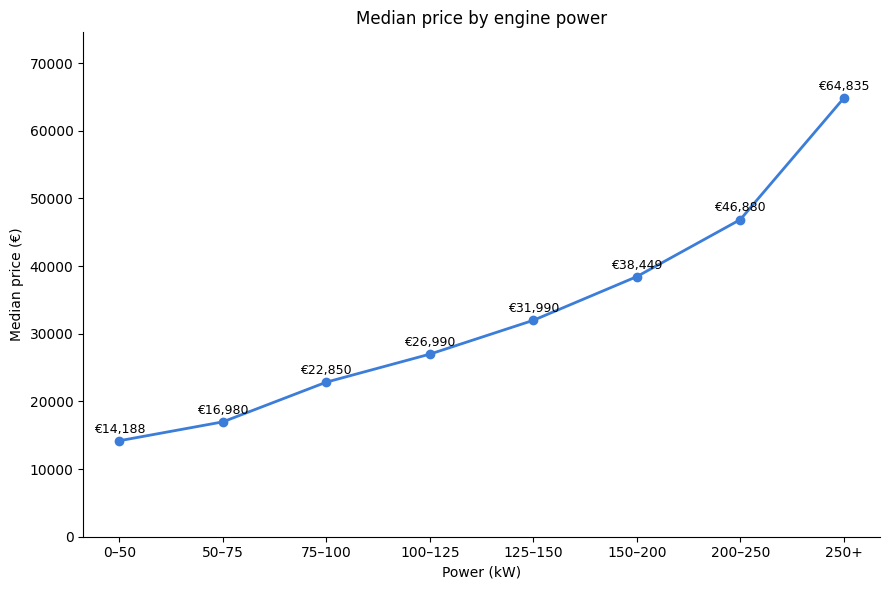

In [ ]:
import pandas as pd, matplotlib.pyplot as plt, seaborn as sns

a = merged[merged["matched"]].copy()
a["power_kw"] = pd.to_numeric(a["power_kw"], errors="coerce")
a = a.dropna(subset=["power_kw"])

bins = [0, 50, 75, 100, 125, 150, 200, 250, 600]
labels = ["0–50", "50–75", "75–100", "100–125", "125–150", "150–200", "200–250", "250+"]
a["band"] = pd.cut(a["power_kw"], bins, labels=labels, include_lowest=True)

trend = a.groupby("band", observed=True)["price_in_euro"].median().reset_index()

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(trend["band"].astype(str), trend["price_in_euro"], marker="o", color="#3b7dd8", linewidth=2)

for x, y in zip(trend["band"].astype(str), trend["price_in_euro"]):
    ax.text(x, y + 1200, f"€{y:,.0f}", ha="center", fontsize=9)

ax.set_title("Median price by engine power")
ax.set_xlabel("Power (kW)")
ax.set_ylabel("Median price (€)")
ax.set_ylim(0, trend["price_in_euro"].max() * 1.15)
sns.despine(); plt.tight_layout(); plt.show()

This is very interesting, is shows power has a direct link to price, at the higher end of power I understand this as most of these cars are luxury/sports cars with a naturally higher cost, this is the closest correlation I have seen.

In [ ]:
a = merged[merged["matched"]].copy()

body = (a.groupby("body_type")["price_in_euro"]
          .agg(cars="size", mean="mean", median="median", min="min", max="max")
          .round(0)
          .sort_values("median", ascending=False))
print(body)
print("Cars with no body type:", a["body_type"].isna().sum())


            cars     mean   median      min        max
body_type                                             
PICKUP       187  56015.0  52980.0  39188.0    85549.0
ROADSTER      70  47431.0  47415.0  34860.0    69999.0
COUPE        531  43781.0  42650.0  12990.0   148700.0
SEDAN       4719  38196.0  33900.0  11500.0  1010101.0
SUV        17075  39486.0  32990.0   7999.0   299999.0
MPV         1563  33150.0  31970.0   6350.0   127900.0
HATCHBACK  32441  23473.0  21990.0   2950.0   315890.0
Cars with no body type: 15202


The body types pickup,coupe and roadster are the most expensive, I suspect this to the roadsters and coupes being sports cars with more power and made by luxury brands, for the pickups i suspect them being more expensive as they are work vehicles.

On the other side of the scale we see hatchbacks being the cheapest body type probably due to the fact that they arre the smallest and cost them less to manufacture making them an overall cheaper car from new.

I was shocked to see thay SUV's were in the middle, i expected them to be more expensive due to the demand for them amongst families.

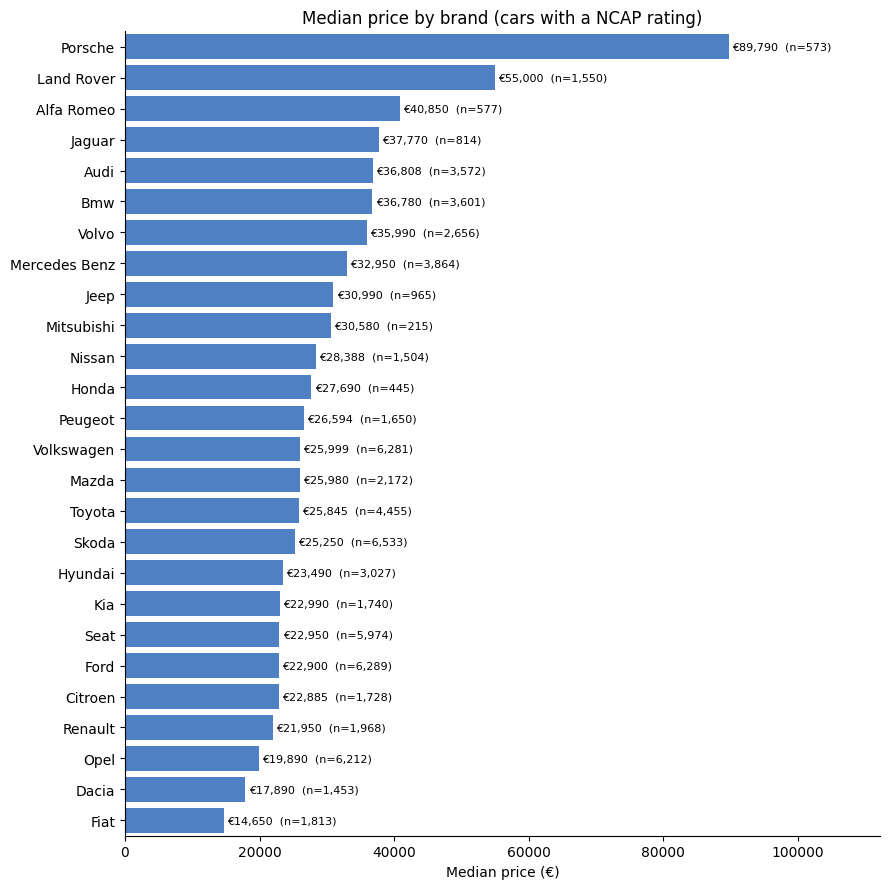

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

a = merged[merged["matched"]].copy()
a["brand"] = a["brand"].str.replace("-", " ").str.title()

brand = (a.groupby("brand")["price_in_euro"]
           .agg(median="median", cars="size").reset_index())
brand = brand[brand["cars"] >= 200].sort_values("median", ascending=False)   # drop tiny brands

fig, ax = plt.subplots(figsize=(9, 9))
sns.barplot(data=brand, y="brand", x="median", color="#3b7dd8", ax=ax)

for i, row in enumerate(brand.itertuples()):
    ax.text(row.median + 500, i, f"€{row.median:,.0f}  (n={row.cars:,})", va="center", fontsize=8)

ax.set_title("Median price by brand (cars with a NCAP rating)")
ax.set_xlabel("Median price (€)")
ax.set_ylabel("")
ax.set_xlim(0, brand["median"].max() * 1.25)
sns.despine(); plt.tight_layout(); plt.show()

As we see from this graph, the luxury brands tend to hold their value more in the used car market, with porsche, land rover, alfa romeo and jaguar having the highest median price, this is due to them being sought after and more expensive to buy new, helping them maintain a higher overall premium.

## Overall

In conclusion, I dont believe the Euro Ncap rating affects the price too much, it is possible in a larger dataset with more newer cars (from 2017 and up) then it could possibly see more conecctions to the prices.

From this I see the main areas that affect prices are: power, brand, mileage & year. This makes the most sense as most people car about the age and use of a car more than a safety rating it has been given, and then for power and brand, we can see luxry car brand and high power cars are the most expensive, due to the price from new and the demand  allows people to set the price at whatever they please.

To sum this up, in this project, the Euro NCAP does NOT affect price of used cars.